# Практичне завдання 2
## Багатокласова логістична регресія та федеративне навчання

**Виконав:** Новак Сергій, ФЕІ-43с  
**Варіант даних:** Dry Bean Dataset

### Мета

Самостійно реалізувати багатокласову логістичну регресію засобами `numpy`, побудувати централізовану базову модель, змоделювати федеративне навчання методом FedAvg і дослідити вплив неоднорідності даних та кількості локальних епох.

### Що реалізовано

- повний EDA та обґрунтований відбір ознак без використання тестової вибірки;
- стратифікований поділ на **Global Test (20%)**, **Global Validation (15%)** і **FL Train Pool (65%)**;
- власна векторизована реалізація `softmax`, cross-entropy, Ridge, градієнтів і mini-batch GD;
- перевірка градієнтів методом скінченних різниць;
- підбір гіперпараметрів централізованої моделі лише за Global Validation;
- IID і Non-IID розподіли між клієнтами;
- власна реалізація FedAvg;
- обов'язкові експерименти для $\alpha\in\{5,1,0.3\}$ та $E\in\{1,5,10\}$;
- порівняння локальних, глобальної федеративної та централізованої моделей;
- відповіді на всі теоретичні питання.

> `scikit-learn` використовується лише для розбиття, масштабування, mutual information та метрик. Готові класи `LogisticRegression` / `SGDClassifier` не використовуються.

## 1. Дані та відтворюваність

Використано [Dry Bean Dataset з UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/602/dry+bean) — офіційне джерело того самого набору, який наведений в умові через Kaggle. Набір містить 13 611 зерен квасолі, 16 числових морфологічних ознак і 7 класів. Це доречний набір для федеративної симуляції: прикладів достатньо для кількох клієнтів, задача є багатокласовою, а Non-IID сценарій природно моделює різні локальні частоти сортів.

Для повної відтворюваності всі генератори випадкових чисел отримують фіксоване зерно `SEED = 42`.

In [1]:
from pathlib import Path
from itertools import product
import copy
import os
import random
import time
import warnings

# Тримаємо кеш Matplotlib у проєкті, щоб Jupyter не залежав від прав на профіль ОС.
MPL_CONFIG_DIR = Path("tmp/matplotlib").resolve()
MPL_CONFIG_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CONFIG_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    log_loss,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

print("Середовище готове. NumPy:", np.__version__, "| pandas:", pd.__version__)

Середовище готове. NumPy: 2.3.5 | pandas: 3.0.1


In [2]:
DATA_CANDIDATES = [
    Path("data/dry_bean_dataset/DryBeanDataset/Dry_Bean_Dataset.xlsx"),
    Path("data/Dry_Bean_Dataset.xlsx"),
]

data_path = next((path for path in DATA_CANDIDATES if path.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "Dry_Bean_Dataset.xlsx не знайдено. Запускайте ноутбук із кореня проєкту "
        "або помістіть файл у data/Dry_Bean_Dataset.xlsx."
    )

df = pd.read_excel(data_path)
TARGET = "Class"
feature_columns = [column for column in df.columns if column != TARGET]

print("Файл:", data_path.resolve())
print("Розмір:", df.shape)
display(df.head())

Файл: D:\University\4thYear\ML2\ml-2\data\dry_bean_dataset\DryBeanDataset\Dry_Bean_Dataset.xlsx
Розмір: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.2910,208.1781,173.8887,1.1972,0.5498,28715,190.1411,0.7639,0.9889,0.9580,0.9134,0.0073,0.0031,0.8342,0.9987,SEKER
1,28734,638.0180,200.5248,182.7344,1.0974,0.4118,29172,191.2728,0.7840,0.9850,0.8870,0.9539,0.0070,0.0036,0.9099,0.9984,SEKER
2,29380,624.1100,212.8261,175.9311,1.2097,0.5627,29690,193.4109,0.7781,0.9896,0.9478,0.9088,0.0072,0.0030,0.8259,0.9991,SEKER
3,30008,645.8840,210.5580,182.5165,1.1536,0.4986,30724,195.4671,0.7827,0.9767,0.9039,0.9283,0.0070,0.0032,0.8618,0.9942,SEKER
4,30140,620.1340,201.8479,190.2793,1.0608,0.3337,30417,195.8965,0.7731,0.9909,0.9849,0.9705,0.0067,0.0037,0.9419,0.9992,SEKER


### 1.1 Первинний аудит

Спочатку перевіряємо типи, пропуски, дублікати та баланс класів. Видалення повних дублікатів до розбиття запобігає ситуації, коли однаковий об'єкт потрапить і до навчання, і до тесту. Це не використовує статистики тесту для навчання моделі.

,dtype,missing,unique
Area,int64,0,12011
Perimeter,float64,0,13416
MajorAxisLength,float64,0,13543
MinorAxisLength,float64,0,13543
AspectRation,float64,0,13543
Eccentricity,float64,0,13543
ConvexArea,int64,0,12066
EquivDiameter,float64,0,12011
Extent,float64,0,13535
Solidity,float64,0,13526


Кількість пропущених значень: 0
Кількість повних дублікатів: 68
Розмір після видалення дублікатів: (13543, 17)


,count,percent
Class,,
BARBUNYA,1322,9.7615
BOMBAY,522,3.8544
CALI,1630,12.0357
DERMASON,3546,26.1833
HOROZ,1860,13.7340
SEKER,2027,14.9671
SIRA,2636,19.4639


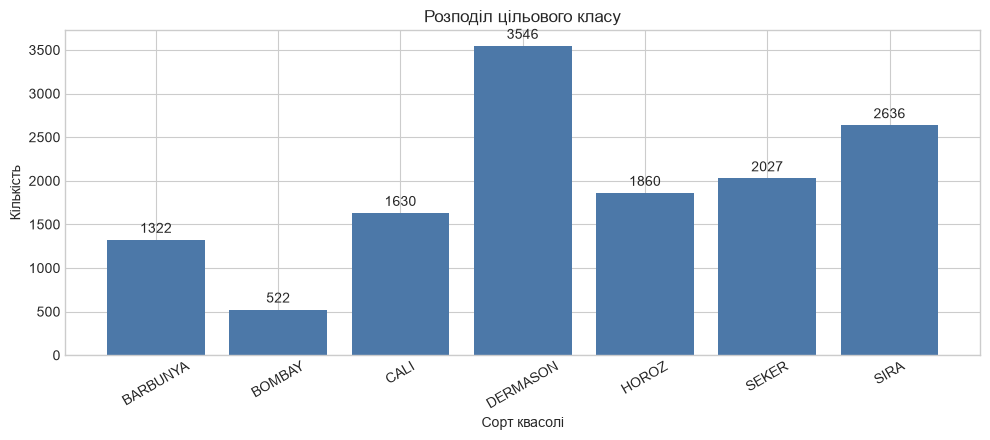

In [3]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
})
display(audit)

duplicate_count = int(df.duplicated().sum())
print("Кількість пропущених значень:", int(df.isna().sum().sum()))
print("Кількість повних дублікатів:", duplicate_count)

clean_df = df.drop_duplicates().reset_index(drop=True)
print("Розмір після видалення дублікатів:", clean_df.shape)

class_counts = clean_df[TARGET].value_counts().sort_index()
class_percent = 100 * class_counts / len(clean_df)
class_table = pd.DataFrame({"count": class_counts, "percent": class_percent})
display(class_table)

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(class_counts.index, class_counts.values, color="#4C78A8")
ax.bar_label(bars, padding=3)
ax.set(title="Розподіл цільового класу", xlabel="Сорт квасолі", ylabel="Кількість")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Висновок.** Пропусків і категоріальних вхідних ознак немає, тому імпутація та one-hot encoding ознак не потрібні. Класи незбалансовані: `DERMASON` представлений значно частіше за `BOMBAY`. Через це, крім accuracy, обов'язково використовуємо macro-F1 та balanced accuracy — вони не дозволяють великим класам повністю домінувати в оцінці.

,count,mean,std,min,25%,50%,75%,max
Area,"13,543.0000","53,048.4604","29,392.4383","20,420.0000","36,282.5000","44,580.0000","61,382.0000","254,616.0000"
Perimeter,"13,543.0000",854.9934,214.7227,524.7360,703.2300,793.8960,977.1465,"1,985.3700"
MajorAxisLength,"13,543.0000",319.8956,85.8093,183.6012,253.0868,296.4046,376.3125,738.8602
MinorAxisLength,"13,543.0000",202.3653,45.0516,122.5127,175.8864,192.4911,217.2454,460.1985
AspectRation,"13,543.0000",1.5811,0.2452,1.0249,1.4307,1.5499,1.7039,2.4303
Eccentricity,"13,543.0000",0.7503,0.0919,0.2190,0.7151,0.7640,0.8097,0.9114
ConvexArea,"13,543.0000","53,767.9867","29,844.2485","20,684.0000","36,673.0000","45,122.0000","62,360.0000","263,261.0000"
EquivDiameter,"13,543.0000",253.0341,59.3077,161.2438,214.9333,238.2457,279.5604,569.3744
Extent,"13,543.0000",0.7498,0.0489,0.5553,0.7187,0.7599,0.7868,0.8662
Solidity,"13,543.0000",0.9872,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947


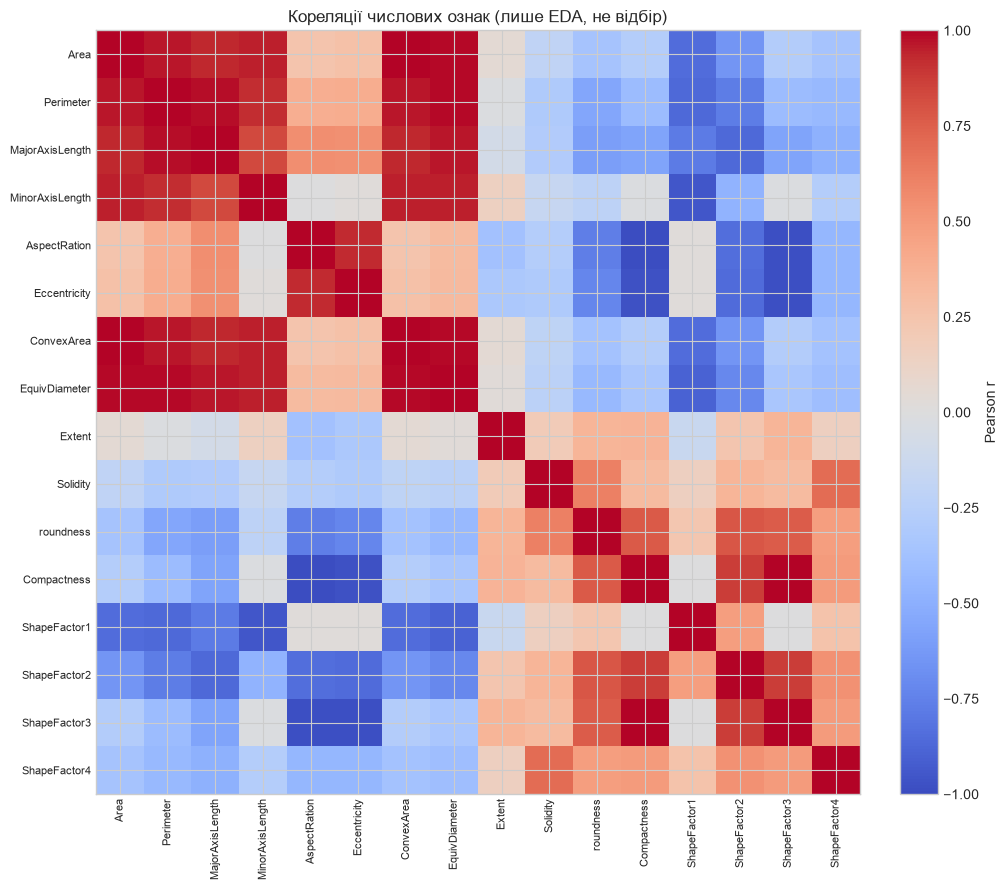

In [4]:
display(clean_df[feature_columns].describe().T)

corr_full = clean_df[feature_columns].corr()
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(corr_full, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_columns)), feature_columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(feature_columns)), feature_columns, fontsize=8)
ax.set_title("Кореляції числових ознак (лише EDA, не відбір)")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="Pearson r")
plt.tight_layout()
plt.show()

**Висновок.** Масштаби ознак дуже різні: площа вимірюється десятками тисяч, а shape factors — малими дробами. Для градієнтного спуску потрібна стандартизація. На тепловій карті очікувано видно сильні зв'язки між геометричними розмірними характеристиками (`Area`, `ConvexArea`, `EquivDiameter`, частково `Perimeter`), отже мультиколінеарність треба контролювати. Сам відбір нижче виконується **тільки на FL Train Pool**.

## 2. Розбиття без Data Leakage

**Data Leakage** — потрапляння інформації з валідаційної/тестової вибірки у процес навчання або вибору моделі. Воно робить метрики нереалістично оптимістичними. Тому порядок такий:

1. виділити Global Test та Global Validation зі стратифікацією;
2. виконати відбір ознак лише за FL Train Pool;
3. навчити scaler лише на FL Train Pool;
4. незмінно застосувати ті самі ознаки й параметри scaler до validation/test.

Тестова вибірка відкривається лише для фінального звіту і ніколи не використовується для підбору гіперпараметрів.

,subset,count,percent
0,FL Train Pool,8802,64.9930
1,Global Validation,2032,15.0041
2,Global Test,2709,20.0030


,FL Train Pool,Global Validation,Global Test
BARBUNYA,859,198,265
BOMBAY,340,78,104
CALI,1059,245,326
DERMASON,2305,532,709
HOROZ,1209,279,372
SEKER,1317,304,406
SIRA,1713,396,527


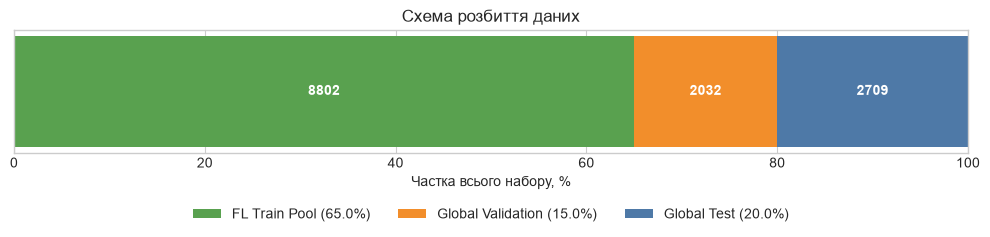

In [5]:
class_names = np.array(sorted(clean_df[TARGET].unique()))
class_to_id = {name: index for index, name in enumerate(class_names)}

X_all = clean_df[feature_columns].copy()
y_all = clean_df[TARGET].map(class_to_id).to_numpy(dtype=int)

# Спочатку 20% для фінального Global Test.
X_remaining, X_test_raw, y_remaining, y_test = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    random_state=SEED,
    stratify=y_all,
)

# 0.1875 * 80% = 15% від повного набору; решта 65% — FL Train Pool.
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.1875,
    random_state=SEED,
    stratify=y_remaining,
)

split_table = pd.DataFrame({
    "subset": ["FL Train Pool", "Global Validation", "Global Test"],
    "count": [len(y_train), len(y_val), len(y_test)],
})
split_table["percent"] = 100 * split_table["count"] / len(clean_df)
display(split_table)

split_class_counts = pd.DataFrame({
    "FL Train Pool": pd.Series(class_names[y_train]).value_counts(),
    "Global Validation": pd.Series(class_names[y_val]).value_counts(),
    "Global Test": pd.Series(class_names[y_test]).value_counts(),
}).fillna(0).astype(int).sort_index()
display(split_class_counts)

fig, ax = plt.subplots(figsize=(10, 2.8))
left = 0
colors = ["#59A14F", "#F28E2B", "#4E79A7"]
for (_, row), color in zip(split_table.iterrows(), colors):
    width = row["percent"]
    ax.barh([0], [width], left=left, color=color, label=f"{row['subset']} ({width:.1f}%)")
    ax.text(left + width / 2, 0, f"{int(row['count'])}", ha="center", va="center", color="white", fontweight="bold")
    left += width
ax.set_xlim(0, 100)
ax.set_yticks([])
ax.set_xlabel("Частка всього набору, %")
ax.set_title("Схема розбиття даних")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=3)
plt.tight_layout()
plt.show()

**Висновок.** Стратифікація зберігає приблизно однакові пропорції кожного сорту у трьох множинах. Global Test зберігається на сервері для фінальної оцінки, Global Validation — для вибору налаштувань і моніторингу, а лише FL Train Pool розподіляється між клієнтами.

## 3. Відбір ознак і масштабування

Для виявлення мультиколінеарності використовуємо лише `X_train_raw`. Якщо абсолютна кореляція пари перевищує 0.98, одну з ознак пари відкидаємо. Зв'язок із категоріальною ціллю оцінюємо mutual information: на відміну від Pearson correlation з довільними номерами класів, вона не створює штучного порядку сортів і може відображати нелінійні залежності.

Поріг |r|: 0.98
Відкинуті через мультиколінеарність: ['ConvexArea', 'EquivDiameter', 'Compactness', 'ShapeFactor3']
Залишено ознак: 12 із 16


,feature,mutual_information
0,Perimeter,1.0595
1,Area,1.0246
2,MajorAxisLength,0.9882
3,ShapeFactor2,0.9377
4,MinorAxisLength,0.9270
5,ShapeFactor1,0.9216
6,AspectRation,0.8060
7,Eccentricity,0.8059
8,roundness,0.7995
9,ShapeFactor4,0.3593


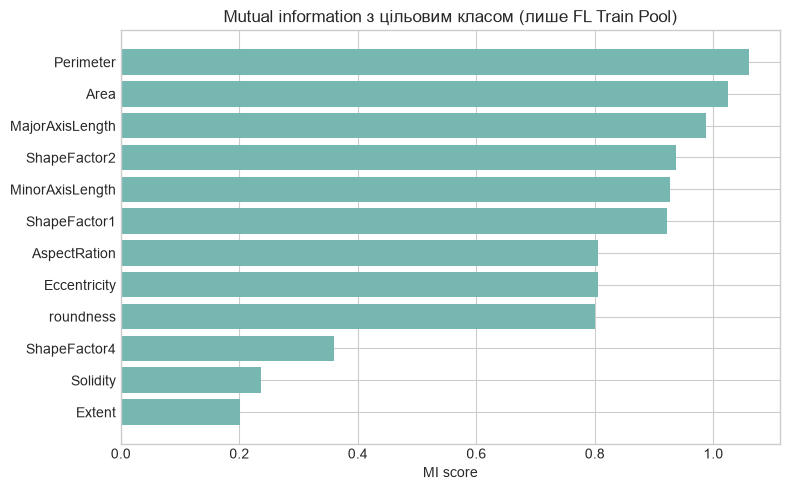

In [6]:
train_corr = X_train_raw.corr().abs()
upper_triangle = train_corr.where(np.triu(np.ones(train_corr.shape), k=1).astype(bool))
correlation_threshold = 0.98
features_to_drop = [
    column for column in upper_triangle.columns
    if (upper_triangle[column] > correlation_threshold).any()
]
selected_features = [column for column in feature_columns if column not in features_to_drop]

mi_scores = mutual_info_classif(
    X_train_raw[selected_features], y_train, random_state=SEED
)
mi_table = (
    pd.DataFrame({"feature": selected_features, "mutual_information": mi_scores})
    .sort_values("mutual_information", ascending=False)
    .reset_index(drop=True)
)

print("Поріг |r|:", correlation_threshold)
print("Відкинуті через мультиколінеарність:", features_to_drop)
print("Залишено ознак:", len(selected_features), "із", len(feature_columns))
display(mi_table)

fig, ax = plt.subplots(figsize=(8, 5))
ordered = mi_table.sort_values("mutual_information")
ax.barh(ordered["feature"], ordered["mutual_information"], color="#76B7B2")
ax.set(title="Mutual information з цільовим класом (лише FL Train Pool)", xlabel="MI score")
plt.tight_layout()
plt.show()

**Висновок.** Відбір прибирає лише майже дублюючі розмірні характеристики, зменшуючи нестійкість коефіцієнтів і зайві обчислення. Ознаки зберігаються не за довільним номером класу, а за їхньою інформаційною залежністю від цілі. Ми не відкидаємо слабші ознаки лише через низький індивідуальний MI: у багатовимірній лінійній межі вони можуть доповнювати інші ознаки.

In [7]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw[selected_features])
X_val = scaler.transform(X_val_raw[selected_features])
X_test = scaler.transform(X_test_raw[selected_features])

print("Середнє FL Train після стандартизації (max |mean|):", np.abs(X_train.mean(axis=0)).max())
print("Стандартне відхилення FL Train (min/max):", X_train.std(axis=0).min(), X_train.std(axis=0).max())
print("Розміри:", X_train.shape, X_val.shape, X_test.shape)

Середнє FL Train після стандартизації (max |mean|): 1.7958115996045432e-14
Стандартне відхилення FL Train (min/max): 0.9999999999999999 1.0
Розміри: (8802, 12) (2032, 12) (2709, 12)


**Висновок.** `StandardScaler` навчається виключно на FL Train Pool; validation і test лише перетворюються готовими параметрами. Це спрощений, але дозволений умовою варіант симуляції глобального препроцесингу. У реальній FL-системі клієнти могли б передати серверу лише локальні кількості, суми та суми квадратів, щоб агрегувати середні й дисперсії без передачі сирих даних.

## 4. Власна багатокласова логістична регресія

Для $X\in\mathbb{R}^{m\times d}$:

$$Z=XW+b,\qquad P=\operatorname{softmax}(Z).$$

Стабільний softmax віднімає максимум кожного рядка перед експонентою. Функція втрат із Ridge:

$$J=-\frac1m\sum_{i,c}Y_{ic}\log P_{ic}+\frac{\lambda}{2}\lVert W\rVert_F^2.$$

Градієнти повністю векторизовані:

$$\nabla_WJ=\frac1mX^T(P-Y)+\lambda W,\qquad
\nabla_bJ=\frac1m\sum_i(P_i-Y_i).$$

Цикли використовуються лише за епохами й mini-batch, що дозволено умовою. Зміщення `b` не регуляризується.

In [8]:
class NumpySoftmaxRegression:
    # Багатокласова softmax-регресія з mini-batch GD та Ridge.

    def __init__(self, n_features, n_classes, l2=0.0, random_state=42):
        self.n_features = int(n_features)
        self.n_classes = int(n_classes)
        self.l2 = float(l2)
        self.random_state = int(random_state)
        self.W = np.zeros((self.n_features, self.n_classes), dtype=float)
        self.b = np.zeros(self.n_classes, dtype=float)

    @staticmethod
    def softmax(logits):
        shifted = logits - np.max(logits, axis=1, keepdims=True)
        exp_shifted = np.exp(shifted)
        return exp_shifted / np.sum(exp_shifted, axis=1, keepdims=True)

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        return self.softmax(X @ self.W + self.b)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

    def loss(self, X, y):
        y = np.asarray(y, dtype=int)
        probabilities = np.clip(self.predict_proba(X), 1e-15, 1.0)
        data_loss = -np.mean(np.log(probabilities[np.arange(len(y)), y]))
        ridge_penalty = 0.5 * self.l2 * np.sum(self.W ** 2)
        return float(data_loss + ridge_penalty)

    def gradients(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        probabilities = self.predict_proba(X)
        one_hot = np.eye(self.n_classes, dtype=float)[y]
        residual = probabilities - one_hot
        dW = (X.T @ residual) / len(y) + self.l2 * self.W
        db = residual.mean(axis=0)
        return dW, db

    def update(self, dW, db, learning_rate):
        self.W -= learning_rate * dW
        self.b -= learning_rate * db

    def get_parameters(self):
        return self.W.copy(), self.b.copy()

    def set_parameters(self, parameters):
        W, b = parameters
        if W.shape != self.W.shape or b.shape != self.b.shape:
            raise ValueError("Несумісні розміри параметрів")
        self.W = np.asarray(W, dtype=float).copy()
        self.b = np.asarray(b, dtype=float).copy()

    def fit(
        self,
        X,
        y,
        epochs=100,
        learning_rate=0.05,
        batch_size=128,
        X_val=None,
        y_val=None,
        verbose=False,
    ):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        rng = np.random.default_rng(self.random_state)
        history = {"train_loss": [], "val_loss": [], "val_macro_f1": []}

        for epoch in range(int(epochs)):
            order = rng.permutation(len(y))
            for start in range(0, len(y), int(batch_size)):
                batch_indices = order[start:start + int(batch_size)]
                dW, db = self.gradients(X[batch_indices], y[batch_indices])
                self.update(dW, db, learning_rate)

            history["train_loss"].append(self.loss(X, y))
            if X_val is not None and y_val is not None:
                history["val_loss"].append(self.loss(X_val, y_val))
                history["val_macro_f1"].append(
                    f1_score(y_val, self.predict(X_val), average="macro", zero_division=0)
                )

            if verbose and ((epoch + 1) % 20 == 0 or epoch == 0):
                message = f"epoch={epoch + 1:3d} train_loss={history['train_loss'][-1]:.4f}"
                if history["val_loss"]:
                    message += f" val_loss={history['val_loss'][-1]:.4f}"
                print(message)

        return history

### 4.1 Числова перевірка градієнтів

Аналітичні похідні порівнюються зі скінченними різницями на маленькому штучному наборі. Це незалежна перевірка найкритичнішої частини власної реалізації.

In [9]:
def gradient_check(epsilon=1e-6):
    rng = np.random.default_rng(SEED)
    X_small = rng.normal(size=(7, 4))
    y_small = rng.integers(0, 3, size=7)
    model = NumpySoftmaxRegression(4, 3, l2=0.01, random_state=SEED)
    model.W = rng.normal(scale=0.1, size=model.W.shape)
    model.b = rng.normal(scale=0.1, size=model.b.shape)
    analytic_W, analytic_b = model.gradients(X_small, y_small)

    numeric_W = np.zeros_like(model.W)
    for index in np.ndindex(model.W.shape):
        original = model.W[index]
        model.W[index] = original + epsilon
        loss_plus = model.loss(X_small, y_small)
        model.W[index] = original - epsilon
        loss_minus = model.loss(X_small, y_small)
        model.W[index] = original
        numeric_W[index] = (loss_plus - loss_minus) / (2 * epsilon)

    numeric_b = np.zeros_like(model.b)
    for index in range(len(model.b)):
        original = model.b[index]
        model.b[index] = original + epsilon
        loss_plus = model.loss(X_small, y_small)
        model.b[index] = original - epsilon
        loss_minus = model.loss(X_small, y_small)
        model.b[index] = original
        numeric_b[index] = (loss_plus - loss_minus) / (2 * epsilon)

    max_error = max(
        float(np.max(np.abs(analytic_W - numeric_W))),
        float(np.max(np.abs(analytic_b - numeric_b))),
    )
    return max_error


gradient_error = gradient_check()
print(f"Максимальна абсолютна похибка градієнта: {gradient_error:.3e}")
assert gradient_error < 1e-6, "Перевірка градієнтів не пройдена"
print("Перевірку пройдено.")

Максимальна абсолютна похибка градієнта: 1.760e-10
Перевірку пройдено.


In [10]:
def evaluate_probabilities(y_true, probabilities):
    predictions = np.argmax(probabilities, axis=1)
    return {
        "accuracy": accuracy_score(y_true, predictions),
        "macro_f1": f1_score(y_true, predictions, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "log_loss": log_loss(y_true, probabilities, labels=np.arange(len(class_names))),
    }


def evaluate_model(model, X, y):
    return evaluate_probabilities(y, model.predict_proba(X))


def plot_confusion(ax, y_true, y_pred, title):
    matrix = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
    image = ax.imshow(matrix, cmap="Blues")
    ax.set_xticks(range(len(class_names)), class_names, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(class_names)), class_names, fontsize=8)
    ax.set(xlabel="Передбачений клас", ylabel="Справжній клас", title=title)
    threshold = matrix.max() / 2
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            ax.text(
                column,
                row,
                matrix[row, column],
                ha="center",
                va="center",
                fontsize=7,
                color="white" if matrix[row, column] > threshold else "black",
            )
    return image

## 5. Централізована базова модель

Підбираємо learning rate, batch size і $\lambda$ лише за **Global Validation**. Основний критерій — macro-F1, додатковий — log-loss. Global Test на цьому етапі не використовується.

In [11]:
n_features = X_train.shape[1]
n_classes = len(class_names)

learning_rates = [0.03, 0.07]
batch_sizes = [128, 256]
l2_values = [0.0, 1e-4, 1e-3]
TUNING_EPOCHS = 60

tuning_rows = []
tuning_histories = {}
start_time = time.perf_counter()

for learning_rate, batch_size, l2 in product(learning_rates, batch_sizes, l2_values):
    candidate = NumpySoftmaxRegression(n_features, n_classes, l2=l2, random_state=SEED)
    history = candidate.fit(
        X_train,
        y_train,
        epochs=TUNING_EPOCHS,
        learning_rate=learning_rate,
        batch_size=batch_size,
        X_val=X_val,
        y_val=y_val,
    )
    metrics = evaluate_model(candidate, X_val, y_val)
    config = (learning_rate, batch_size, l2)
    tuning_histories[config] = history
    tuning_rows.append({
        "learning_rate": learning_rate,
        "batch_size": batch_size,
        "l2": l2,
        **metrics,
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values(
    ["macro_f1", "log_loss"], ascending=[False, True]
).reset_index(drop=True)

best_config = tuning_results.iloc[0][["learning_rate", "batch_size", "l2"]].to_dict()
best_config["batch_size"] = int(best_config["batch_size"])

print(f"Підбір завершено за {time.perf_counter() - start_time:.1f} с")
display(tuning_results)
print("Обрані гіперпараметри:", best_config)

Підбір завершено за 8.4 с


,learning_rate,batch_size,l2,accuracy,macro_f1,balanced_accuracy,log_loss
0,0.0700,128,0.0000,0.9405,0.9496,0.9475,0.2103
1,0.0700,128,0.0001,0.9405,0.9496,0.9475,0.2114
2,0.0700,128,0.0010,0.9390,0.9486,0.9462,0.2219
3,0.0700,256,0.0000,0.9375,0.9469,0.9444,0.2338
4,0.0700,256,0.0001,0.9375,0.9469,0.9444,0.2347
5,0.0700,256,0.0010,0.9375,0.9466,0.9441,0.2426
6,0.0300,128,0.0000,0.9365,0.9460,0.9435,0.2422
7,0.0300,128,0.0001,0.9365,0.9460,0.9435,0.2430
8,0.0300,128,0.0010,0.9355,0.9448,0.9420,0.2503
9,0.0300,256,0.0000,0.9345,0.9443,0.9421,0.2895


Обрані гіперпараметри: {'learning_rate': 0.07, 'batch_size': 128, 'l2': 0.0}


**Висновок.** Конфігурація обирається за найбільшим validation macro-F1, а не за test accuracy. Ridge може трохи покращити узагальнення та стримує великі ваги за наявності корельованих ознак; надто велике $\lambda$ спричинило б underfitting. Batch size визначає компроміс між шумністю оновлень і швидкістю обчислень.

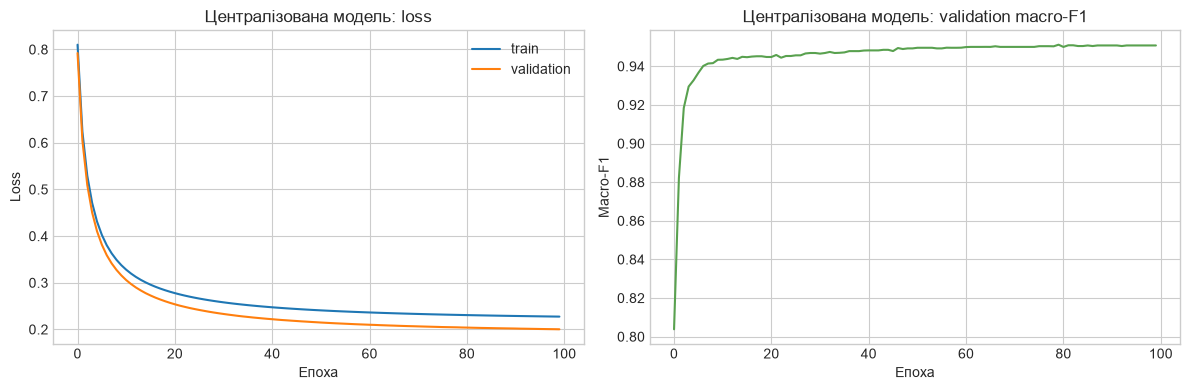

,accuracy,macro_f1,balanced_accuracy,log_loss
Centralized,0.9173,0.9287,0.9273,0.2339


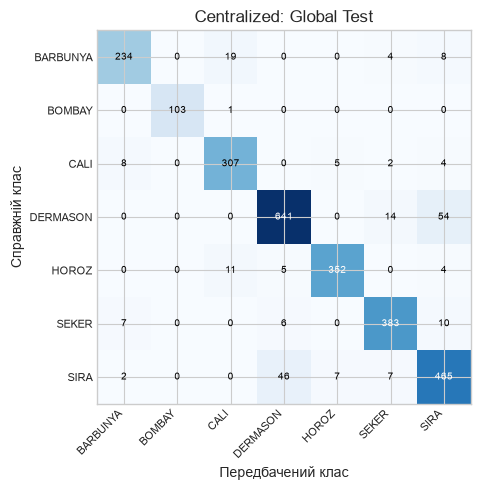

In [12]:
CENTRAL_EPOCHS = 100
central_model = NumpySoftmaxRegression(
    n_features,
    n_classes,
    l2=best_config["l2"],
    random_state=SEED,
)
central_history = central_model.fit(
    X_train,
    y_train,
    epochs=CENTRAL_EPOCHS,
    learning_rate=best_config["learning_rate"],
    batch_size=best_config["batch_size"],
    X_val=X_val,
    y_val=y_val,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(central_history["train_loss"], label="train")
axes[0].plot(central_history["val_loss"], label="validation")
axes[0].set(title="Централізована модель: loss", xlabel="Епоха", ylabel="Loss")
axes[0].legend()
axes[1].plot(central_history["val_macro_f1"], color="#59A14F")
axes[1].set(title="Централізована модель: validation macro-F1", xlabel="Епоха", ylabel="Macro-F1")
plt.tight_layout()
plt.show()

central_test_metrics = evaluate_model(central_model, X_test, y_test)
display(pd.DataFrame([central_test_metrics], index=["Centralized"]))

fig, ax = plt.subplots(figsize=(6, 5))
plot_confusion(ax, y_test, central_model.predict(X_test), "Centralized: Global Test")
plt.tight_layout()
plt.show()

**Висновок.** Криві показують збіжність cross-entropy та поведінку на даних, яких модель не бачить у навчанні. Якщо validation loss перестає зменшуватись, додаткові епохи вже майже не дають користі. Confusion matrix показує не тільки загальну точність, а й конкретні пари сортів, які лінійній моделі найважче розрізнити.

## 6. Розподіл FL Train Pool між клієнтами

Архітектура симуляції:

```text
                     Global Validation / Global Test
                                  ↑
Клієнт 0 ─┐                       Сервер
Клієнт 1 ─┼─ локальні ваги ──> FedAvg ──> глобальні W, b
   ...    │                         │
Клієнт K ─┘ <──── глобальні W, b ───┘
```

Сирі клієнтські вибірки логічно ізольовані: функція навчання отримує від клієнта лише оновлені параметри й розмір локальної вибірки. Сервер використовує validation для моніторингу, test — лише для фінальної оцінки.

In [13]:
def iid_partition(y, n_clients=5, seed=42):
    # Стратифікований IID-розподіл: кожен клас ділиться між усіма клієнтами.
    rng = np.random.default_rng(seed)
    partitions = [[] for _ in range(n_clients)]
    for class_id in np.unique(y):
        class_indices = np.flatnonzero(y == class_id)
        rng.shuffle(class_indices)
        for client_id, chunk in enumerate(np.array_split(class_indices, n_clients)):
            partitions[client_id].extend(chunk.tolist())
    result = []
    for indices in partitions:
        indices = np.asarray(indices, dtype=int)
        rng.shuffle(indices)
        result.append(indices)
    return result


def dirichlet_partition(y, n_clients=5, alpha=0.3, seed=42, min_size=10, max_attempts=1000):
    # Non-IID-розподіл класів за Dirichlet(alpha).
    rng = np.random.default_rng(seed)
    for _ in range(max_attempts):
        partitions = [[] for _ in range(n_clients)]
        for class_id in np.unique(y):
            class_indices = np.flatnonzero(y == class_id)
            rng.shuffle(class_indices)
            proportions = rng.dirichlet(np.full(n_clients, alpha))
            counts = rng.multinomial(len(class_indices), proportions)
            boundaries = np.cumsum(counts)[:-1]
            for client_id, chunk in enumerate(np.split(class_indices, boundaries)):
                partitions[client_id].extend(chunk.tolist())
        if min(map(len, partitions)) >= min_size:
            result = []
            for indices in partitions:
                indices = np.asarray(indices, dtype=int)
                rng.shuffle(indices)
                result.append(indices)
            return result
    raise RuntimeError("Не вдалося отримати розподіл із заданим мінімальним розміром")


def validate_partition(partitions, n_samples):
    combined = np.concatenate(partitions)
    assert len(combined) == n_samples, "Втрачено приклади"
    assert len(np.unique(combined)) == n_samples, "Приклад потрапив до кількох клієнтів"
    assert np.array_equal(np.sort(combined), np.arange(n_samples)), "Некоректні індекси"


def client_class_table(partitions, y):
    rows = []
    for client_id, indices in enumerate(partitions):
        counts = np.bincount(y[indices], minlength=n_classes)
        rows.append(counts)
    table = pd.DataFrame(rows, columns=class_names)
    table.index = [f"Client {index}" for index in range(len(partitions))]
    table["Total"] = table.sum(axis=1)
    return table


N_CLIENTS = 5
iid_clients = iid_partition(y_train, n_clients=N_CLIENTS, seed=SEED)
non_iid_clients = dirichlet_partition(
    y_train, n_clients=N_CLIENTS, alpha=0.3, seed=SEED + 300
)
validate_partition(iid_clients, len(y_train))
validate_partition(non_iid_clients, len(y_train))

print("IID")
display(client_class_table(iid_clients, y_train))
print("Non-IID, alpha=0.3")
display(client_class_table(non_iid_clients, y_train))

IID


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,Total
Client 0,172,68,212,461,242,264,343,1762
Client 1,172,68,212,461,242,264,343,1762
Client 2,172,68,212,461,242,263,343,1761
Client 3,172,68,212,461,242,263,342,1760
Client 4,171,68,211,461,241,263,342,1757


Non-IID, alpha=0.3


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,Total
Client 0,342,190,4,1862,49,221,479,3147
Client 1,120,0,49,132,729,8,804,1842
Client 2,24,6,0,2,17,328,4,381
Client 3,0,0,1006,286,414,73,46,1825
Client 4,373,144,0,23,0,687,380,1607


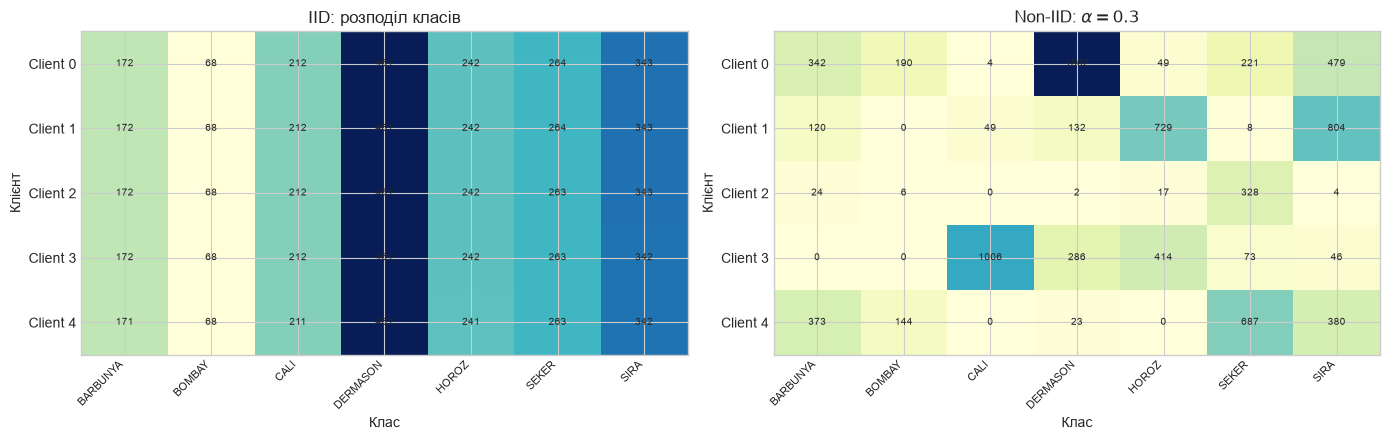

In [14]:
def plot_client_heatmap(ax, table, title):
    values = table[class_names].to_numpy()
    image = ax.imshow(values, cmap="YlGnBu", aspect="auto")
    ax.set_xticks(range(len(class_names)), class_names, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(table.index)), table.index)
    ax.set_title(title)
    ax.set_xlabel("Клас")
    ax.set_ylabel("Клієнт")
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            ax.text(column, row, values[row, column], ha="center", va="center", fontsize=7)
    return image


iid_table = client_class_table(iid_clients, y_train)
non_iid_table = client_class_table(non_iid_clients, y_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_client_heatmap(axes[0], iid_table, "IID: розподіл класів")
plot_client_heatmap(axes[1], non_iid_table, r"Non-IID: $\alpha=0.3$")
plt.tight_layout()
plt.show()

assert min(non_iid_table["Total"]) >= 10

**Висновок.** У IID-сценарії кожен клієнт бачить майже глобальні пропорції класів. При $\alpha=0.3$ окремі класи концентруються у небагатьох клієнтів, а деякі клієнти майже не бачать певних сортів. Кожен об'єкт належить рівно одному клієнту, мінімальний розмір перевірено assertion. Така статистична неоднорідність створює різноспрямовані локальні градієнти й може погіршувати FedAvg.

## 7. FedAvg і симуляція федеративного навчання

Для вибраних у раунді клієнтів сервер обчислює:

$$W^{t+1}=\sum_{k\in S_t}\frac{n_k}{\sum_j n_j}W_k^{t+1},\qquad
b^{t+1}=\sum_{k\in S_t}\frac{n_k}{\sum_j n_j}b_k^{t+1}.$$

Зважування потрібне, бо оновлення клієнта з 2000 прикладами має представляти більшу частину глобальної емпіричної функції втрат, ніж оновлення клієнта зі 100 прикладами. Просте середнє надало б малим клієнтам непропорційно великий вплив.

In [15]:
def fedavg(parameter_sets, sample_counts):
    # Зважене за кількістю прикладів середнє W і b.
    weights = np.asarray(sample_counts, dtype=float)
    weights /= weights.sum()
    aggregated_W = sum(weight * params[0] for weight, params in zip(weights, parameter_sets))
    aggregated_b = sum(weight * params[1] for weight, params in zip(weights, parameter_sets))
    return aggregated_W, aggregated_b


# Малий детермінований тест агрегації.
toy_parameters = [
    (np.ones((2, 2)), np.ones(2)),
    (np.full((2, 2), 3.0), np.full(2, 3.0)),
]
toy_W, toy_b = fedavg(toy_parameters, [1, 3])
assert np.allclose(toy_W, 2.5) and np.allclose(toy_b, 2.5)


def federated_train(
    X_train,
    y_train,
    X_val,
    y_val,
    partitions,
    rounds,
    local_epochs,
    learning_rate,
    batch_size,
    l2,
    seed=42,
):
    global_model = NumpySoftmaxRegression(
        X_train.shape[1], n_classes, l2=l2, random_state=seed
    )
    history_rows = []
    final_local_models = []

    for round_index in range(rounds):
        global_parameters = global_model.get_parameters()
        local_parameters = []
        local_sizes = []
        local_models = []

        for client_id, indices in enumerate(partitions):
            # Клієнт отримує тільки глобальні параметри та власні локальні дані.
            local_model = NumpySoftmaxRegression(
                X_train.shape[1],
                n_classes,
                l2=l2,
                random_state=seed + round_index * 100 + client_id,
            )
            local_model.set_parameters(global_parameters)
            local_model.fit(
                X_train[indices],
                y_train[indices],
                epochs=local_epochs,
                learning_rate=learning_rate,
                batch_size=min(batch_size, len(indices)),
            )
            local_parameters.append(local_model.get_parameters())
            local_sizes.append(len(indices))
            local_models.append(local_model)

        global_model.set_parameters(fedavg(local_parameters, local_sizes))
        validation_metrics = evaluate_model(global_model, X_val, y_val)
        history_rows.append({"round": round_index + 1, **validation_metrics})
        final_local_models = local_models

    return global_model, pd.DataFrame(history_rows), final_local_models

## 8. Обов'язкові експерименти

В усіх сценаріях використовуємо однакову кількість клієнтів, раундів та налаштування оптимізатора. Змінюємо лише досліджуваний фактор. Кожний фінальний варіант оцінюється на Global Test один раз після завершення навчання; результати тесту не впливають на вибір параметрів.

In [16]:
FED_ROUNDS = 25
FED_LEARNING_RATE = min(float(best_config["learning_rate"]), 0.05)
FED_BATCH_SIZE = int(best_config["batch_size"])
FED_L2 = float(best_config["l2"])

partition_sets = {
    "IID": iid_partition(y_train, N_CLIENTS, SEED),
    "alpha=5": dirichlet_partition(y_train, N_CLIENTS, 5.0, SEED + 5000),
    "alpha=1": dirichlet_partition(y_train, N_CLIENTS, 1.0, SEED + 1000),
    "alpha=0.3": dirichlet_partition(y_train, N_CLIENTS, 0.3, SEED + 300),
}
for partitions in partition_sets.values():
    validate_partition(partitions, len(y_train))

experiment_cache = {}


def run_federated(label, local_epochs):
    key = (label, int(local_epochs))
    if key not in experiment_cache:
        experiment_cache[key] = federated_train(
            X_train,
            y_train,
            X_val,
            y_val,
            partition_sets[label],
            rounds=FED_ROUNDS,
            local_epochs=local_epochs,
            learning_rate=FED_LEARNING_RATE,
            batch_size=FED_BATCH_SIZE,
            l2=FED_L2,
            seed=SEED,
        )
    return experiment_cache[key]


start_time = time.perf_counter()
for label in ["IID", "alpha=5", "alpha=1", "alpha=0.3"]:
    run_federated(label, local_epochs=5)
for local_epochs in [1, 5, 10]:
    run_federated("alpha=0.3", local_epochs=local_epochs)
print(f"Федеративні експерименти завершено за {time.perf_counter() - start_time:.1f} с")

Федеративні експерименти завершено за 8.0 с


### 8.1 Вплив неоднорідності даних

Порівнюємо IID та Dirichlet $\alpha=5,1,0.3$ за фіксованих $E=5$. Велике $\alpha$ дає близькі пропорції класів, мале — концентрує класи в окремих клієнтів.

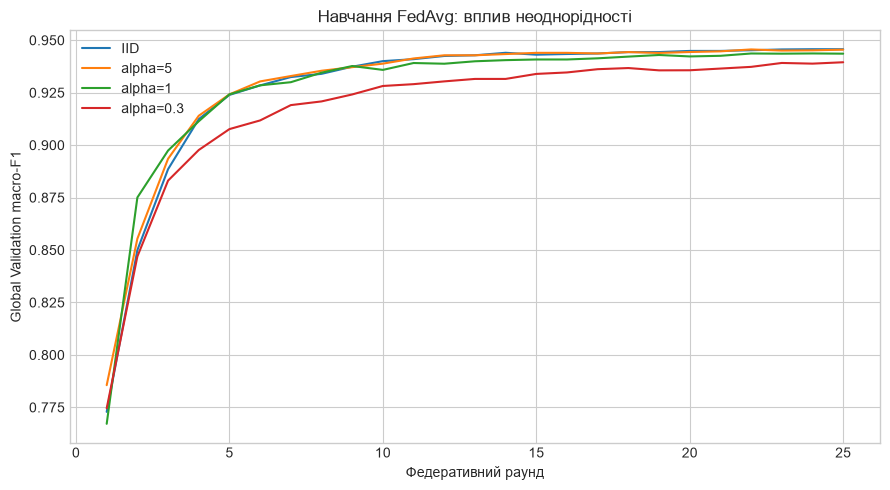

,accuracy,macro_f1,balanced_accuracy,log_loss
scenario,,,,
IID,0.9133,0.9251,0.9235,0.2954
alpha=5,0.9129,0.9247,0.9231,0.2946
alpha=1,0.9107,0.9224,0.9201,0.2934
alpha=0.3,0.9144,0.9264,0.9239,0.3119


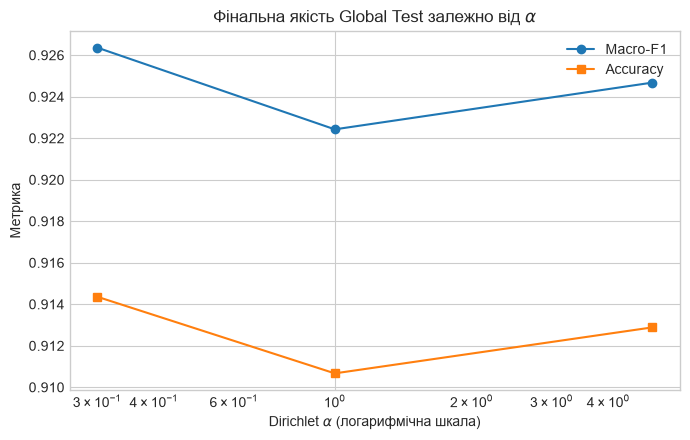

In [17]:
alpha_test_rows = []
fig, ax = plt.subplots(figsize=(9, 5))

for label in ["IID", "alpha=5", "alpha=1", "alpha=0.3"]:
    model, history, _ = run_federated(label, local_epochs=5)
    ax.plot(history["round"], history["macro_f1"], label=label)
    alpha_test_rows.append({"scenario": label, **evaluate_model(model, X_test, y_test)})

ax.set(
    title="Навчання FedAvg: вплив неоднорідності",
    xlabel="Федеративний раунд",
    ylabel="Global Validation macro-F1",
)
ax.legend()
plt.tight_layout()
plt.show()

alpha_test_results = pd.DataFrame(alpha_test_rows).set_index("scenario")
display(alpha_test_results)

dirichlet_only = alpha_test_results.loc[["alpha=5", "alpha=1", "alpha=0.3"]].copy()
dirichlet_only.index = [5.0, 1.0, 0.3]
dirichlet_only = dirichlet_only.sort_index()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(dirichlet_only.index, dirichlet_only["macro_f1"], marker="o", label="Macro-F1")
ax.plot(dirichlet_only.index, dirichlet_only["accuracy"], marker="s", label="Accuracy")
ax.set_xscale("log")
ax.set(
    title=r"Фінальна якість Global Test залежно від $\alpha$",
    xlabel=r"Dirichlet $\alpha$ (логарифмічна шкала)",
    ylabel="Метрика",
)
ax.legend()
plt.tight_layout()
plt.show()

**Висновок.** Зменшення $\alpha$ робить локальні розподіли класів різнішими. Тоді кожний клієнт оптимізує дещо іншу локальну задачу, а середнє локальних кроків є гіршим наближенням до централізованого градієнта. Через це збіжність може стати менш гладкою, а глобальна модель — поступитися централізованій. Водночас конкретний локальний клієнт може бути кращим на власному вузькому розподілі, але гіршим на глобальному тесті.

### 8.2 Вплив кількості локальних епох

Для сильного Non-IID ($\alpha=0.3$) порівнюємо $E=1,5,10$. Більше локальних епох зменшує частоту комунікації, але може посилювати **client drift** — відхилення локальної моделі в напрямку специфічного локального розподілу.

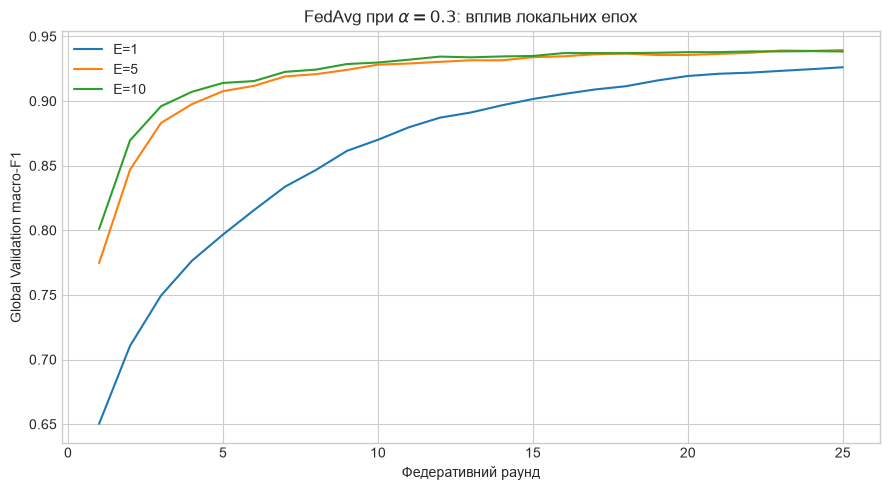

,accuracy,macro_f1,balanced_accuracy,log_loss
local_epochs,,,,
1,0.8985,0.9110,0.9063,0.4838
5,0.9144,0.9264,0.9239,0.3119
10,0.9140,0.9267,0.9248,0.2785


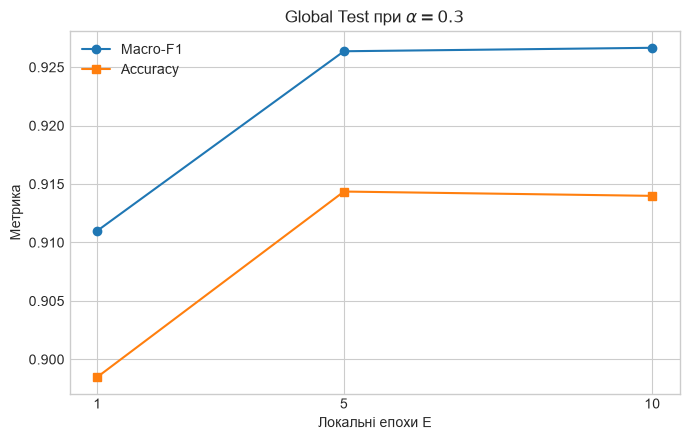

In [18]:
epoch_test_rows = []
fig, ax = plt.subplots(figsize=(9, 5))

for local_epochs in [1, 5, 10]:
    model, history, _ = run_federated("alpha=0.3", local_epochs=local_epochs)
    ax.plot(history["round"], history["macro_f1"], label=f"E={local_epochs}")
    epoch_test_rows.append({"local_epochs": local_epochs, **evaluate_model(model, X_test, y_test)})

ax.set(
    title=r"FedAvg при $\alpha=0.3$: вплив локальних епох",
    xlabel="Федеративний раунд",
    ylabel="Global Validation macro-F1",
)
ax.legend()
plt.tight_layout()
plt.show()

epoch_test_results = pd.DataFrame(epoch_test_rows).set_index("local_epochs")
display(epoch_test_results)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(epoch_test_results.index, epoch_test_results["macro_f1"], marker="o", label="Macro-F1")
ax.plot(epoch_test_results.index, epoch_test_results["accuracy"], marker="s", label="Accuracy")
ax.set(
    title=r"Global Test при $\alpha=0.3$",
    xlabel="Локальні епохи E",
    ylabel="Метрика",
)
ax.set_xticks([1, 5, 10])
ax.legend()
plt.tight_layout()
plt.show()

**Висновок.** $E=1$ робить кожне локальне оновлення близьким до глобального напрямку, але за один раунд прогрес невеликий. $E=5$ часто є компромісом. За $E=10$ клієнти довше оптимізують власні нерепрезентативні дані; при сильному Non-IID це може посилити client drift і погіршити агрегацію. Фактичний результат залежить від learning rate і датасету, тому висновок робимо з таблиці, а не припускаємо наперед.

## 9. Локальні, глобальна та централізована моделі

Для порівняння беремо складний сценарій $\alpha=0.3$, $E=5$. Окремі локальні моделі навчаються з нуля лише на даних свого клієнта; їхні гіперпараметри успадковані від централізованого validation-підбору, а не підбираються на тесті. Сервер оцінює отримані моделі на Global Test, не передаючи тест клієнтам.

,samples,accuracy,macro_f1,balanced_accuracy,log_loss
model,,,,,
Local client 0,3147,0.7885,0.7143,0.7785,0.7335
Local client 1,1842,0.7202,0.6243,0.6480,1.1613
Local client 2,381,0.4079,0.3611,0.5475,1.7570
Local client 3,1825,0.6829,0.5037,0.5769,2.0969
Local client 4,1607,0.4714,0.4111,0.5591,2.0037


,accuracy,macro_f1,balanced_accuracy,log_loss
model,,,,
Local mean,0.6142,0.5229,0.6220,1.5505
"Global FedAvg (alpha=0.3, E=5)",0.9144,0.9264,0.9239,0.3119
Centralized,0.9173,0.9287,0.9273,0.2339


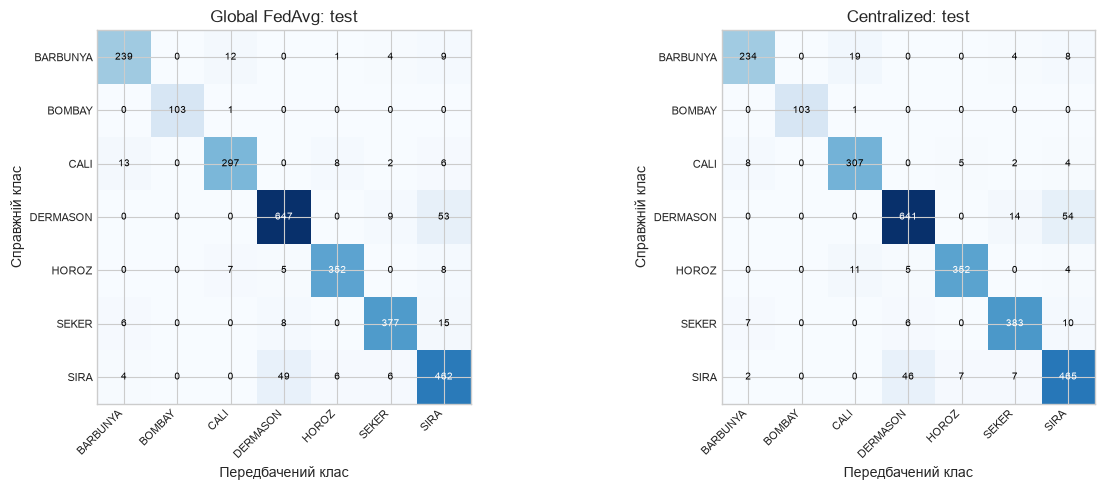

In [19]:
comparison_partitions = partition_sets["alpha=0.3"]
local_test_rows = []
local_models = []

for client_id, indices in enumerate(comparison_partitions):
    local_model = NumpySoftmaxRegression(
        n_features,
        n_classes,
        l2=best_config["l2"],
        random_state=SEED + client_id,
    )
    local_model.fit(
        X_train[indices],
        y_train[indices],
        epochs=CENTRAL_EPOCHS,
        learning_rate=best_config["learning_rate"],
        batch_size=min(best_config["batch_size"], len(indices)),
    )
    local_models.append(local_model)
    local_test_rows.append({
        "model": f"Local client {client_id}",
        "samples": len(indices),
        **evaluate_model(local_model, X_test, y_test),
    })

local_test_results = pd.DataFrame(local_test_rows).set_index("model")
display(local_test_results)

fed_model, _, _ = run_federated("alpha=0.3", local_epochs=5)
fed_test_metrics = evaluate_model(fed_model, X_test, y_test)

comparison_results = pd.DataFrame([
    {"model": "Local mean", **local_test_results.drop(columns="samples").mean().to_dict()},
    {"model": "Global FedAvg (alpha=0.3, E=5)", **fed_test_metrics},
    {"model": "Centralized", **central_test_metrics},
]).set_index("model")
display(comparison_results)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_confusion(axes[0], y_test, fed_model.predict(X_test), "Global FedAvg: test")
plot_confusion(axes[1], y_test, central_model.predict(X_test), "Centralized: test")
plt.tight_layout()
plt.show()

**Висновок.** Локальні моделі зазвичай гірші на глобальному тесті, бо кожна бачить лише частину об'єктів і викривлений набір класів. FedAvg об'єднує знання без передавання сирих даних і має значно репрезентативнішу межу рішень. Централізована модель часто залишається верхньою базовою лінією, оскільки кожен її gradient step одночасно враховує весь FL Train Pool і не страждає від client drift.

## 10. Відповіді на теоретичні питання

1. **Чому softmax для багатокласової класифікації?** Він перетворює довільні logits на невід'ємні ймовірності, сума яких дорівнює 1, і дозволяє класам конкурувати між собою.

2. **Чому cross-entropy є природною функцією втрат?** Вона є від'ємним log-likelihood категоріального розподілу. Мінімізуючи її, ми максимізуємо ймовірність правильних міток і сильніше штрафуємо впевнені неправильні прогнози.

3. **Ridge проти Lasso.** Ridge додає $\lambda\lVert W\rVert_2^2/2$, плавно стискає ваги й добре працює з корельованими ознаками. Lasso додає $\lambda\lVert W\rVert_1$, може занулювати окремі коефіцієнти й виконувати розріджений відбір ознак, але є недиференційованим у нулі.

4. **Чому `b` не регуляризують?** Зміщення задає базовий рівень logits і не збільшує чутливість до ознак. Його штрафування залежало б від довільного центрування даних і могло б змістити апріорні ймовірності класів.

5. **Що таке Data Leakage?** Це використання під час навчання інформації, яка в реальному прогнозуванні недоступна, наприклад статистик scaler з test. Наслідок — завищена оцінка якості.

6. **Чому test не використовують для гіперпараметрів?** Тоді гіперпараметри неявно підлаштовуються до test, і він перестає бути незалежною оцінкою узагальнення. Для вибору є validation.

7. **Чому scaler навчають тільки на train?** Середні та дисперсії є параметрами, навченими з даних. Якщо додати validation/test, їхній розподіл просочиться у train pipeline.

8. **Що таке федеративне навчання та його переваги?** Клієнти навчаються локально, а сервер агрегує оновлення. Переваги: сирі дані не централізуються, менше юридичних/організаційних бар'єрів, можливість навчатися на розподілених джерелах. Саме по собі FL не гарантує приватності; для цього потрібні secure aggregation, differential privacy тощо.

9. **Чому сервер не отримує сирі дані?** Це основна межа довіри FL: вона зменшує ризик витоку чутливих записів і потребу переносити великі локальні набори. Водночас самі gradients/weights також можуть витікати, тому в реальних системах їх захищають.

10. **Чому FedAvg зважує за кількістю прикладів?** Так локальна функція втрат кожного клієнта входить у глобальну ціль пропорційно кількості прикладів, які вона представляє.

11. **Що буде без зважування?** Клієнт із 50 записами матиме той самий вплив, що й клієнт із 5000; результат оптимізуватиме середнє клієнтів, а не середнє прикладів, і може бути упередженим до малих вузлів.

12. **Що таке Non-IID?** Дані різних клієнтів не є вибірками з одного й того самого розподілу: відрізняються частоти класів, ознак, обсяги або залежність між $X$ та $y$.

13. **Чому Non-IID погіршує FL?** Локальні градієнти стають різноспрямованими; кілька локальних кроків ведуть моделі до різних локальних оптимумів, а їх усереднення може не відповідати доброму глобальному кроку.

14. **Що таке client drift?** Надмірне відхилення локальної моделі від поточної глобальної через багато оптимізаційних кроків на нерепрезентативних локальних даних.

15. **Як впливає кількість локальних епох?** Більше $E$ дає більше обчислень на один раунд і може прискорити прогрес при IID, але підсилює drift при Non-IID. Менше $E$ стабільніше, але потребує більше комунікаційних раундів.

16. **Чи може глобальна модель бути гіршою за централізовану?** Так. Централізована модель бачить точний глобальний gradient, а FedAvg — усереднені параметри після локальних траєкторій; неповна участь, Non-IID, велике $E$ та мало раундів створюють розрив.

17. **Які метрики потрібні при дисбалансі?** Macro-F1 однаково враховує класи, balanced accuracy усереднює recall класів, confusion matrix показує типи помилок, log-loss оцінює якість імовірностей. Звичайну accuracy залишаємо для інтерпретації, але не використовуємо окремо.

## 11. Загальний висновок

Нижче висновок генерується з фактично отриманих метрик, тому після `Run All` числа завжди відповідають результатам поточного запуску.

In [20]:
best_alpha_scenario = alpha_test_results["macro_f1"].idxmax()
best_epoch_count = int(epoch_test_results["macro_f1"].idxmax())
central_f1 = central_test_metrics["macro_f1"]
fed_f1 = fed_test_metrics["macro_f1"]
local_f1 = float(local_test_results["macro_f1"].mean())

display(Markdown(fr'''
Власна `numpy`-реалізація успішно пройшла числову перевірку градієнтів
(максимальна похибка **{gradient_error:.2e}**). Централізована модель на Global Test
отримала accuracy **{central_test_metrics['accuracy']:.4f}**, macro-F1 **{central_f1:.4f}**,
balanced accuracy **{central_test_metrics['balanced_accuracy']:.4f}** та log-loss
**{central_test_metrics['log_loss']:.4f}**.

У серії з неоднорідністю найвищий test macro-F1 серед розглянутих сценаріїв має
**{best_alpha_scenario}**. Для сильного Non-IID найкращим серед $E=1,5,10$ за test
macro-F1 виявилося **E={best_epoch_count}**. Це експериментальний результат саме для
цього набору, seed та бюджету у {FED_ROUNDS} раундів, а не універсальне правило.

У складному сценарії $\alpha=0.3$, $E=5$ глобальна FedAvg-модель має macro-F1
**{fed_f1:.4f}**, середня окрема локальна модель — **{local_f1:.4f}**, а централізована —
**{central_f1:.4f}**. Отже, агрегація справді переносить знання між клієнтами без
централізації сирих даних, але статистична неоднорідність і client drift можуть створювати
розрив відносно централізованої базової лінії.
'''))


Власна `numpy`-реалізація успішно пройшла числову перевірку градієнтів
(максимальна похибка **1.76e-10**). Централізована модель на Global Test
отримала accuracy **0.9173**, macro-F1 **0.9287**,
balanced accuracy **0.9273** та log-loss
**0.2339**.

У серії з неоднорідністю найвищий test macro-F1 серед розглянутих сценаріїв має
**alpha=0.3**. Для сильного Non-IID найкращим серед $E=1,5,10$ за test
macro-F1 виявилося **E=10**. Це експериментальний результат саме для
цього набору, seed та бюджету у 25 раундів, а не універсальне правило.

У складному сценарії $\alpha=0.3$, $E=5$ глобальна FedAvg-модель має macro-F1
**0.9264**, середня окрема локальна модель — **0.5229**, а централізована —
**0.9287**. Отже, агрегація справді переносить знання між клієнтами без
централізації сирих даних, але статистична неоднорідність і client drift можуть створювати
розрив відносно централізованої базової лінії.


## 12. Як відтворити

1. Встановити залежності з `requirements.txt` у вибраному Python-середовищі.
2. Переконатися, що файл даних є за шляхом `data/dry_bean_dataset/DryBeanDataset/Dry_Bean_Dataset.xlsx`.
3. У VS Code вибрати це середовище як Jupyter kernel.
4. Виконати **Restart Kernel and Run All Cells**.

З фіксованим seed таблиці й графіки мають відтворитися. Незначні відмінності останніх знаків можливі між версіями числових бібліотек.